// Copyright (c) 2022 Robert Bosch GmbH

// SPDX-License-Identifier: AGPL-3.0

# Analysis

This notebook conducts the causal analysis by computing the Average Treatment Effect (ATE) values described in the README. The main execution block is situated in the final cell; consequently, all preceding cells must be executed sequentially prior to running this terminal block. The final results for all evaluated interventions are exported to a plain text file (results.txt).

## Scenario Description Pre-processing

The following cell determines the pedestrian's scenario based on the *nuScenes* metadata. To simplify the analysis, a single scenario description is assigned to each pedestrian. The annotations are processed according to the following rules:

* **Precedence Hierarchy:** Overlapping scenarios are resolved by applying a strict hierarchy of precedence. **Construction** is prioritized first, followed by **bridge**, and lastly **crosswalk**.
* **Default Classification:** If a pedestrian is not associated with any other defined scenario, they are classified by default as being on a **sidewalk**.
* **Data Filtering:** This step filters out the "mix" (i.e., multiple occluding objects at once) category and "others" (i.e., occluding objects with low frequency of occurrence).

The second cell is reserved for analyzing overlapping scenarios, exporting a CSV file that can be further examined using Excel. Our analysis indicates that overlapping scenarios between construction, bridge, and crosswalk account for only $2\%$ across our 5000 annotated samples, hence supporting the precedence hierarchy approach.


In [ ]:
import pandas as pd
import ast
df = pd.read_csv('Final_5k_annotated_occlusions.csv',sep=',')


scenario_list = []
for row_index,row in df.iterrows():
    scene = ast.literal_eval(row.to_dict()["scene_desc"])

    
    if "construction" in df.loc[row_index].to_dict()["scene_desc"]:
        scenario_list.append("construction")
        #break
    elif "Construction" in df.loc[row_index].to_dict()["scene_desc"]:
        scenario_list.append("construction")
        #break
    elif "bridge" in df.loc[row_index].to_dict()["scene_desc"]:
        scenario_list.append("bridge")
    elif "Bridge" in df.loc[row_index].to_dict()["scene_desc"]:
        scenario_list.append("bridge")
        #break
    elif "crosswalk" in df.loc[row_index].to_dict()["scene_desc"]:
        scenario_list.append("crosswalk")
        #break
    else:
        scenario_list.append("sidewalk")
        
# Only consider the 12 most relevant synthetic half-occluding objects     
indices_to_drop = df[(df['occluding_object'] != "car") & (df['occluding_object'] != "human") &
                     (df['occluding_object'] != "concrete barrier") & (df['occluding_object'] != "construction barrier") & 
                     (df['occluding_object'] != "fence") & (df['occluding_object'] != "bush") & 
                     (df['occluding_object'] != "pole") & (df['occluding_object'] != "tree") &
                     (df['occluding_object'] != "traffic sign") & (df['occluding_object'] != "construction fence") &
                     (df['occluding_object'] != "building") & (df['occluding_object'] != "trash can")].index


df["scenario"] = scenario_list
df.drop(indices_to_drop, inplace=True)
#df.to_csv("5k_annotated_FINAL_with_scenario_collumn-automated-sidewalk.csv", index=False)


In [ ]:
import pandas as pd
import ast
df = pd.read_csv('Final_5k_annotated_occlusions.csv',sep=',')


scenario_list = []
construction_list = []
bridge_list = []
crosswalk_list = []
sidewalk_list = []
for row_index,row in df.iterrows():
    scene = ast.literal_eval(row.to_dict()["scene_desc"])

    #TODO, check if "construction" is within ' truck and construction workers''
    if "construction" in df.loc[row_index].to_dict()["scene_desc"] or "Construction" in df.loc[row_index].to_dict()["scene_desc"]:        
        construction_list.append(1)
    else:
        construction_list.append(0)
        
    if "bridge" in df.loc[row_index].to_dict()["scene_desc"] or "Bridge" in df.loc[row_index].to_dict()["scene_desc"]:
        bridge_list.append(1)
        
    else: 
        bridge_list.append(0)
        #break
    if "crosswalk" in df.loc[row_index].to_dict()["scene_desc"]:
        crosswalk_list.append(1)
        
    else:
        crosswalk_list.append(0)
    
    #TODO, check if "construction" is within ' truck and construction workers''
    if "construction" in df.loc[row_index].to_dict()["scene_desc"]:
        scenario_list.append("construction")
        sidewalk_list.append(0)
        #break
    elif "Construction" in df.loc[row_index].to_dict()["scene_desc"]:
        scenario_list.append("construction")
        sidewalk_list.append(0)
        #break
    elif "bridge" in df.loc[row_index].to_dict()["scene_desc"]:
        scenario_list.append("bridge")
        sidewalk_list.append(0)
    elif "Bridge" in df.loc[row_index].to_dict()["scene_desc"]:
        scenario_list.append("bridge")
        sidewalk_list.append(0)
        #break
    elif "crosswalk" in df.loc[row_index].to_dict()["scene_desc"]:
        scenario_list.append("crosswalk")
        sidewalk_list.append(0)
        #break
    else:
        scenario_list.append("sidewalk")
        sidewalk_list.append(1)
    

        
# Only consider the 12 most relevant synthetic half-occluding objects     
indices_to_drop = df[(df['occluding_object'] != "car") & (df['occluding_object'] != "human") &
                     (df['occluding_object'] != "concrete barrier") & (df['occluding_object'] != "construction barrier") & 
                     (df['occluding_object'] != "fence") & (df['occluding_object'] != "bush") & 
                     (df['occluding_object'] != "pole") & (df['occluding_object'] != "tree") &
                     (df['occluding_object'] != "traffic sign") & (df['occluding_object'] != "construction fence") &
                     (df['occluding_object'] != "building") & (df['occluding_object'] != "trash can")].index


df["scenario"] = scenario_list
df["construction"] = construction_list
df["bridge"] = bridge_list
df["crosswalk"] = crosswalk_list
df["sidewalk"] = sidewalk_list
df.drop(indices_to_drop, inplace=True)

#df.to_csv("5k_scenario_overlap_analysis.csv", index=False)


# Compute the conditional probability given scene conditions

The conditional probability is computed from the following manually annotated sample

*"5k_annotated_FINAL_with_scenario_collumn-automated-sidewalk.csv"*

In [1]:
import pandas as pd
def get_prob(scene_conditions):
    list_objects = ["human", "car", "concrete barrier", "fence", "construction barrier",  "bush", "tree", "construction fence", 
                "pole", "building", "trash can", "traffic sign"]
    df = pd.read_csv("5k_annotated_FINAL_with_scenario_collumn-automated-sidewalk.csv")
    
    total_nr_samples = len(df)
    nr_samples_scene_conditions = len(df[(df["is_night"] == scene_conditions["is_night"]) &
                                       (df["is_rain"] == scene_conditions["is_rain"]) &
                                       (df["scenario"] == scene_conditions["Scenario"])])
    
    prob_scene_conditions = nr_samples_scene_conditions/total_nr_samples
    #print("marginal probability of scene conditions is: {}".format(prob_scene_conditions))
    
    

    prob_list = []
    prob_dic = {}
    for occluding_object in list_objects:
        prob_occluding_object = len(df[df["occluding_object"] == occluding_object])/total_nr_samples
        #print("marginal probability of {} is: {}".format(occluding_object,prob_occluding_object))
        
        
        
        
        nr_samples_occludion_join_scene = len(df[ (df["occluding_object"] == occluding_object) & 
                                        (df["is_night"] == scene_conditions["is_night"]) &
                                        (df["is_rain"] == scene_conditions["is_rain"]) &
                                        (df["scenario"] == scene_conditions["Scenario"])])
        joint_perc_occlusion =   nr_samples_occludion_join_scene/total_nr_samples
        
        
        
        # Smoothed Probability = (Original Count + alpha) / (Total Samples in condition + Number of Categories)
        alpha = 1
        try:
            
            #Original probability without smoothing
            #cond_prob_occluding_object = joint_perc_occlusion/prob_scene_conditions
            
            #Probability with smoothing
            cond_prob_occluding_object = (nr_samples_occludion_join_scene + alpha) / (nr_samples_scene_conditions + len(list_objects))
        except:
            # These exception occure when there is zero samples for the scene conditions,prob_scene_condition=0 (i.e divisionbyzero error)
            
            #if scene_conditions["is_night"] = 0:
            day_scene = 0
            nr_samples_occludion_join_scene = len(df[ (df["occluding_object"] == occluding_object) & 
                                        (df["is_night"] == day_scene) &
                                        (df["is_rain"] == scene_conditions["is_rain"]) &
                                        (df["scenario"] == scene_conditions["Scenario"])])
            nr_samples_scene_conditions = len(df[(df["is_night"] == day_scene) &
                                       (df["is_rain"] == scene_conditions["is_rain"]) &
                                       (df["scenario"] == scene_conditions["Scenario"])])
            cond_prob_occluding_object = (nr_samples_occludion_join_scene + alpha) / (nr_samples_scene_conditions + len(list_objects))
            
        prob_list.append(cond_prob_occluding_object)
        prob_dic[occluding_object] = cond_prob_occluding_object
    #print(sum(prob_list))
    #return prob_list
    return prob_dic

### test functions for *get_prob*

In [ ]:
scene_conditions = {"is_night": 0, "is_rain": 0, "Scenario": "sidewalk"}
#scene_conditions = {"is_night": 0, "is_rain": 0, "Scenario": "construction"}
#scene_conditions = {"is_night": 0, "is_rain": 0, "Scenario": "bridge"}
#scene_conditions = {"is_night": 0, "is_rain": 1, "Scenario": "sidewalk"}
#scene_conditions = {"is_night": 0, "is_rain": 1, "Scenario": "sidewalk"}


prob_dic = get_prob(scene_conditions)

print(prob_dic)

print(sum(get_prob(scene_conditions).values()))

## Visualization of conditional probability

The following cell visualizes the conditional probability of a occluding object given the following scene conditions: *is_night*, *is_rain*, and *scenario*

Number of samples for scene conditions: 1030


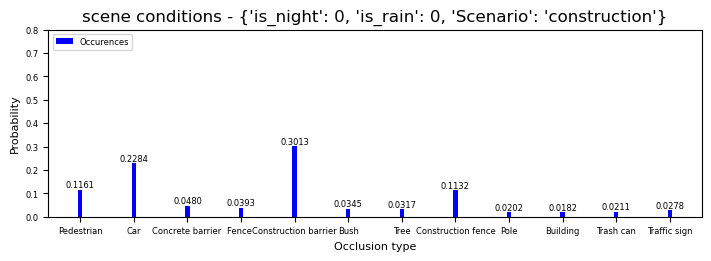

In [4]:

list_objects = ["human", "car", "concrete barrier", "fence", "construction barrier",  "bush", "tree", "construction fence", 
                "pole", "building", "trash can", "traffic sign"]
occluding_object = "car"
df = pd.read_csv("5k_annotated_FINAL_with_scenario_collumn-automated-sidewalk.csv")
occluding_object = "car"
scene_conditions = {"is_night": 0, "is_rain": 0, "Scenario": "construction"} 
total_nr_samples = len(df)
nr_samples_scene_conditions = len(df[(df["is_night"] == scene_conditions["is_night"]) &
                                   (df["is_rain"] == scene_conditions["is_rain"]) &
                                   (df["scenario"] == scene_conditions["Scenario"])])

nr_samples_joint = len(df[ (df["occluding_object"] == occluding_object) & 
                                        (df["is_night"] == scene_conditions["is_night"]) &
                                        (df["is_rain"] == scene_conditions["is_rain"]) &
                                        (df["scenario"] == scene_conditions["Scenario"])])

print("Number of samples for scene conditions: {}".format(nr_samples_scene_conditions))
#print("Number of samples of occluding object: {}".format(nr_samples_joint))



prob_list = get_prob(scene_conditions)
prob_dic = {}
for obj,prob in zip(list_objects, prob_list):
    prob_dic[obj] = prob
    

import matplotlib.pyplot as plt
import numpy as np

occurences = {
    'Occurences': tuple(prob_list.values()),
}



x = np.arange(12)  # the label locations
width = 0.08  # the width of the bars


fig, ax = plt.subplots(layout='constrained', figsize=(7,2.5))
multiplier=0
colors = (("b",0.9, 30),)
for (color,alpha,padding), (attribute, measurement) in zip(colors,occurences.items()):
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement, width, label=attribute, color=color, alpha=1)
    ax.bar_label(rects, label_type="edge", fontsize=6, fmt='%.4f')



ax.set_ylabel('Probability', fontsize=8)
ax.set_xlabel('Occlusion type', fontsize=8)
ax.tick_params(labelsize=6)
#ax.set_title('Occlusion type')
ax.set_xticks([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11])
ax.set_xticklabels(["Pedestrian", "Car", "Concrete barrier ", "Fence ", "Construction barrier", 
                    "Bush", "Tree", "Construction fence", 
                    "Pole", "Building", "Trash can", "Traffic sign",],fontsize=6)

ax.legend(loc='upper left', ncols=5, fontsize=6)
ax.set_ylim(0, 0.8)

ax.set_title("scene conditions - " + str(scene_conditions))
#plt.savefig("bar-conditional dist453.pdf", format="pdf", bbox_inches="tight")
plt.show()

## Visualize figure 2 from paper

It can be noticed that marginal and conditional day-clear-sidewalk are quite close to each other. Since most of the scenes contain day-clear-sidewalk, therefore intervention 2 and 1 are similiar to each other.

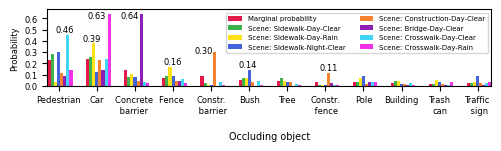

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42







df = pd.read_csv("5k_annotated_FINAL_with_scenario_collumn-automated-sidewalk.csv")
total_nr_samples = len(df)
prob_list = []
marginal_prob = []
list_objects = ["human", "car", "concrete barrier", "fence", "construction barrier", "bush", "tree", "construction fence", 
                "pole", "building", "trash can", "traffic sign"]
for occluding_object in list_objects:
    marginal_prob.append(len(df[df["occluding_object"] == occluding_object])/total_nr_samples)


Sidewalk_Day_Clear = get_prob({"is_night": 0, "is_rain": 0, "Scenario": "sidewalk"})
Sidewalk_Day_rain = get_prob({"is_night": 0, "is_rain": 1, "Scenario": "sidewalk"})
Sidewalk_night_Clear = get_prob({"is_night": 1, "is_rain": 0, "Scenario": "sidewalk"})
construction_Day_Clear = get_prob({"is_night": 0, "is_rain": 0, "Scenario": "construction"})
Bridge_Day_Clear = get_prob({"is_night": 0, "is_rain": 0, "Scenario": "bridge"})
Crosswalk_Day_Clear = get_prob({"is_night": 0, "is_rain": 0, "Scenario": "crosswalk"})
Crosswalk_Day_rain = get_prob({"is_night": 0, "is_rain": 1, "Scenario": "crosswalk"})

prob_distributions = {
    'Intervention 1: Marginal': (0.22, 0.22, 0.14, 0.08, 0.07, 0.05, 0.04, 0.03, 0.03, 0.02, 0.01, 0.02),
    'Scene: Sidewalk-Day-Clear': (0.28, 0.25, 0.08, 0.027, 0.08, 0.07, 0.07, 0.005, 0.03, 0.04, 0.01, 0.03),
    'Scene: Sidewalk-Day-Rain': (0.03, 0.37, 0.10, 0.009, 0.16, 0.06, 0.04, 0.004, 0.06, 0.04, 0.05, 0.03),
    'Scene: Sidewalk-Night-Clear': (0.30, 0.12, 0.08, 0.004, 0.08, 0.14, 0.03, 0.004, 0.08, 0.01, 0.03, 0.08),
    'Scene: Construction-Day-Clear': (0.11, 0.23, 0.04, 0.30, 0.03, 0.03, 0.03, 0.11, 0.02, 0.01, 0.02, 0.02),
    'Scene: Bridge-Day-Clear': (0.08, 0.14, 0.64, 0.002, 0.04, 0.002, 0.002, 0.02, 0.03, 0.008, 0.004, 0.01),
    'Scene: Crosswalk-Day-Clear': (0.46, 0.24, 0.03, 0.03, 0.05, 0.04, 0.01, 0.006, 0.03, 0.02, 0.006, 0.02),
    'Scene: Crosswalk-Day-Rain': (0.14, 0.63, 0.02, 0.01, 0.02, 0.01, 0.01, 0.01, 0.03, 0.01, 0.03, 0.03),
    
}


prob_distributions = {
    'Marginal probability': tuple(marginal_prob),
    'Scene: Sidewalk-Day-Clear': (Sidewalk_Day_Clear["human"], Sidewalk_Day_Clear["car"], Sidewalk_Day_Clear["concrete barrier"],
                                  Sidewalk_Day_Clear["fence"], Sidewalk_Day_Clear["construction barrier"], Sidewalk_Day_Clear["bush"], 
                                  Sidewalk_Day_Clear["tree"], Sidewalk_Day_Clear["construction fence"], Sidewalk_Day_Clear["pole"],
                                  Sidewalk_Day_Clear["building"], Sidewalk_Day_Clear["trash can"], Sidewalk_Day_Clear["traffic sign"]),
    'Scene: Sidewalk-Day-Rain': (Sidewalk_Day_rain["human"], Sidewalk_Day_rain["car"], Sidewalk_Day_rain["concrete barrier"],
                                 Sidewalk_Day_rain["fence"], Sidewalk_Day_rain["construction barrier"],  Sidewalk_Day_rain["bush"], 
                                 Sidewalk_Day_rain["tree"], Sidewalk_Day_rain["construction fence"], Sidewalk_Day_rain["pole"],
                                 Sidewalk_Day_rain["building"], Sidewalk_Day_rain["trash can"], Sidewalk_Day_rain["traffic sign"]),
    
    'Scene: Sidewalk-Night-Clear': (Sidewalk_night_Clear["human"], Sidewalk_night_Clear["car"], Sidewalk_night_Clear["concrete barrier"],
                                    Sidewalk_night_Clear["fence"], Sidewalk_night_Clear["construction barrier"], Sidewalk_night_Clear["bush"], 
                                    Sidewalk_night_Clear["tree"], Sidewalk_night_Clear["construction fence"], Sidewalk_night_Clear["pole"],
                                    Sidewalk_night_Clear["building"], Sidewalk_night_Clear["trash can"], Sidewalk_night_Clear["traffic sign"]),
    
    'Scene: Construction-Day-Clear': (construction_Day_Clear["human"], construction_Day_Clear["car"], construction_Day_Clear["concrete barrier"],
                                      construction_Day_Clear["fence"], construction_Day_Clear["construction barrier"],  construction_Day_Clear["bush"], 
                                      construction_Day_Clear["tree"], construction_Day_Clear["construction fence"], construction_Day_Clear["pole"],
                                      construction_Day_Clear["building"], construction_Day_Clear["trash can"], construction_Day_Clear["traffic sign"]),
    
    'Scene: Bridge-Day-Clear': (Bridge_Day_Clear["human"], Bridge_Day_Clear["car"], Bridge_Day_Clear["concrete barrier"],
                                Bridge_Day_Clear["fence"], Bridge_Day_Clear["construction barrier"],  Bridge_Day_Clear["bush"], 
                                Bridge_Day_Clear["tree"], Bridge_Day_Clear["construction fence"], Bridge_Day_Clear["pole"],
                                Bridge_Day_Clear["building"], Bridge_Day_Clear["trash can"], Bridge_Day_Clear["traffic sign"]),
    
    'Scene: Crosswalk-Day-Clear': (Crosswalk_Day_Clear["human"], Crosswalk_Day_Clear["car"], Crosswalk_Day_Clear["concrete barrier"],
                                   Crosswalk_Day_Clear["fence"], Crosswalk_Day_Clear["construction barrier"], Crosswalk_Day_Clear["bush"], 
                                   Crosswalk_Day_Clear["tree"], Crosswalk_Day_Clear["construction fence"], Crosswalk_Day_Clear["pole"],
                                   Crosswalk_Day_Clear["building"], Crosswalk_Day_Clear["trash can"], Crosswalk_Day_Clear["traffic sign"]),
    
    'Scene: Crosswalk-Day-Rain': (Crosswalk_Day_rain["human"], Crosswalk_Day_rain["car"], Crosswalk_Day_rain["concrete barrier"],
                                  Crosswalk_Day_rain["fence"], Crosswalk_Day_rain["construction barrier"], Crosswalk_Day_rain["bush"], 
                                  Crosswalk_Day_rain["tree"], Crosswalk_Day_rain["construction fence"], Crosswalk_Day_rain["pole"],
                                  Crosswalk_Day_rain["building"], Crosswalk_Day_rain["trash can"], Crosswalk_Day_rain["traffic sign"]),
    
}



x = np.arange(12)  # the label locations
width = 0.08  # the width of the bars
multiplier = -3

fig, ax = plt.subplots(layout='constrained', figsize=(4.9,1.4))
col = [
    '#e6194B',  # Red
    '#3cb44b',  # Green
    '#ffe119',  # Yellow
    '#4363d8',  # Blue
    '#f58231',  # Orange
    '#911eb4',  # Purple
    '#42d4f4',  # Cyan
    '#f032e6'   # Magenta
]
colors = ((col[0],0.9, 30),
          (col[1],0.7, 1),
          (col[2],0.3, 1),
          (col[3],0.7, 1),
          (col[4],0.3, 1),
          (col[5],0.3, 1),
          (col[6],0.7, 1),
          (col[7],0.3, 1),
         )
for (color,alpha,padding), (attribute, measurement) in zip(colors,prob_distributions.items()):
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement, width, label=attribute, color=color, alpha=1)
    #ax.bar_label(rects, padding=padding, label_type="edge", fontsize=6)
    multiplier += 1

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Probability', fontsize=6)
plt.yticks(np.arange(0, 0.7, 0.1))
ax.set_xlabel('Occluding object', fontsize=7)
ax.tick_params(labelsize=6)
#ax.set_title('Occlusion type')
ax.set_xticks([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11])
ax.set_xticklabels(["Pedestrian", "Car", "Concrete \n barrier  \n", "Fence ", "Constr.\n barrier", 
                   "Bush", "Tree", "Constr.\n fence", "Pole", "Building", "Trash\ncan", "Traffic \n sign",],fontsize=6)

ax.legend(loc='upper right', ncols=2, fontsize=5)
ax.set_ylim(0, 0.68)
ax.set_xlim(-0.3, 11.36)

# Annotate text on high values
ax.annotate("0.46",(0.15, 0.46), (0.15, 0.46), 'data', fontsize=6.0, ha='center', va='bottom')
ax.annotate("0.39",(0.85, 0.38), (0.85, 0.38), 'data', fontsize=6.0, ha='center', va='bottom')
ax.annotate("0.63",(1.0, 0.58), (1.0, 0.58), 'data', fontsize=6.0, ha='center', va='bottom')
ax.annotate("0.64",(1.86, 0.58), (1.86, 0.58), 'data', fontsize=6.0, ha='center', va='bottom')
ax.annotate("0.30",(3.8, 0.27), (3.8, 0.27), 'data', fontsize=6.0, ha='center', va='bottom')
ax.annotate("0.16",(3, 0.17), (3, 0.17), 'data', fontsize=6.0, ha='center', va='bottom')
ax.annotate("0.14",(4.95, 0.15), (4.95, 0.15), 'data', fontsize=6.0, ha='center', va='bottom')
ax.annotate("0.11",(7.1, 0.12), (7.1, 0.12), 'data', fontsize=6.0, ha='center', va='bottom')


plt.savefig("intervention - distribution - EDCC4.pdf", format="pdf", bbox_inches="tight", dpi=800)
plt.show()

## Declarative functions

The following cell will declare some function that will be used in the core function "compute_causal effect"

- conditional_intervention()
- extract_metaData()
- CODIF_mapping()

### Conditional interventions

The function below defines the conditional intervention based on domain knowledge. There are two cases

1. Construction worker
2. Pedestrian walk

In [ ]:
def conditional_intervention(obj_dist, camera, is_night, scenario, CODIF_run, rows_list, pedestrian_category, dic_df, row_index):

    # Conditional interventions using domain knowledge
    if obj_dist < 4 and camera == "CAM_FRONT" and scenario == "crosswalk":
        if CODIF_run == False:
            rows_list.append(dic_df["human"].loc[row_index].to_dict())

        else:
            if is_night == 1:
                rows_list.append(dic_df["black human walking"].loc[row_index].to_dict())
            else:
                rows_list.append(dic_df["colour_avg human walking"].loc[row_index].to_dict())
        return True
    if pedestrian_category == "human.pedestrian.construction_worker" and scenario == "construction":
        if CODIF_run == False:
            rows_list.append(dic_df["construction barrier"].loc[row_index].to_dict())
        else:
            if is_night == 1:
                rows_list.append(dic_df["black bottom"].loc[row_index].to_dict())
            else:
                rows_list.append(dic_df["colour_avg bottom"].loc[row_index].to_dict())
        return True
    return False



### Extraction function

This function extracts the nuScenes meta-data


In [ ]:
def extract_metaData(CODIF_run, row):
    if CODIF_run == False:
        #retrive scene information
        scene = ast.literal_eval(row.to_dict()["scene_desc"])
        obj_dist = row.to_dict()["obj_distance"]
        is_night = row.to_dict()["is_night"]
        is_rain = row.to_dict()["is_rain"]
        camera = row.to_dict()["camera"]
        pedestrian_category = row.to_dict()["category"]
        if "construction" in  row.to_dict()["scene_desc"]:
            scenario = "construction"
        elif "Construction" in  row.to_dict()["scene_desc"]:
            scenario = "construction"
        elif "bridge" in  row.to_dict()["scene_desc"]:
            scenario = "bridge"
        elif "Bridge" in row.to_dict()["scene_desc"]:
            scenario = "bridge"
        elif "crosswalk" in  row.to_dict()["scene_desc"]:
            scenario = "crosswalk"
        else:
            scenario = "sidewalk"
        return scene, obj_dist, is_night, is_rain, camera, pedestrian_category, scenario
    else:
        #retrive scene information
        scene = ast.literal_eval(row.to_dict()["scene_desc"])
        obj_dist = row.to_dict()["obj_distance"]
        #print(obj_dist)
        #print(type(obj_dist))
        #obj_dist = float(row.to_dict()["obj_distance"].replace(',', '.'))
        obj_dist = row.to_dict()["obj_distance"]
        is_night = row.to_dict()["is_night"]
        is_rain = row.to_dict()["is_rain"]
        camera = row.to_dict()["camera"]
        pedestrian_category = row.to_dict()["category"]
        if "construction" in  row.to_dict()["scene_desc"]:
            scenario = "construction"
        elif "Construction" in  row.to_dict()["scene_desc"]:
            scenario = "construction"
        elif "bridge" in  row.to_dict()["scene_desc"]:
            scenario = "bridge"
        elif "Bridge" in row.to_dict()["scene_desc"]:
            scenario = "bridge"
        elif "crosswalk" in  row.to_dict()["scene_desc"]:
            scenario = "crosswalk"
        else:
            scenario = "sidewalk"
        return scene, obj_dist, is_night, is_rain, camera, pedestrian_category, scenario

### CODIF mapping


In [ ]:
def CODIF_mapping(is_night, occluding_object, dic_df, row_index, rows_list):
    if is_night == 1 and (occluding_object == "car" or occluding_object == "concrete barrier" or occluding_object == "concrete barrier" or occluding_object == "construction barrier" or occluding_object == "construction barrier" or occluding_object == "bush" or occluding_object == "trash can" or occluding_object == "fence"):
        rows_list.append(dic_df["black bottom"].loc[row_index].to_dict())
    elif is_night == 0 and (occluding_object == "car" or occluding_object == "concrete barrier" or occluding_object == "concrete barrier" or occluding_object == "construction barrier" or occluding_object == "construction barrier" or occluding_object == "bush" or occluding_object == "trash can" or occluding_object == "fence"):
        rows_list.append(dic_df["colour_avg bottom"].loc[row_index].to_dict())
    elif is_night == 1 and occluding_object == "human" :
        rows_list.append(dic_df["black human walking"].loc[row_index].to_dict())
    elif is_night == 0 and occluding_object == "human" :
        rows_list.append(dic_df["colour_avg human walking"].loc[row_index].to_dict())
    elif is_night == 1 and (occluding_object == "traffic sign" or occluding_object == "tree"):
        rows_list.append(dic_df["black vertical middle"].loc[row_index].to_dict())
    elif is_night == 0 and (occluding_object == "traffic sign" or occluding_object == "tree"):
        rows_list.append(dic_df["colour_avg vertical middle"].loc[row_index].to_dict())
    elif is_night == 1 and (occluding_object == "pole" or occluding_object == "building"):
        rows_list.append(dic_df["black side_ways_right"].loc[row_index].to_dict())
    elif is_night == 0 and (occluding_object == "traffic sign" or occluding_object == "tree"):
        rows_list.append(dic_df["colour_avg side_ways_right"].loc[row_index].to_dict())
    return rows_list

## Core function:  *Compute_causal_effect*

This function will be used in the main entry point later i

In [ ]:

import pandas as pd
from random import sample
import math
import random
import json
import ast
import numpy as np

list_objects = ["human", "car", "concrete barrier", "construction barrier", "bush", "fence", "pole", "tree", 
                    "construction fence", "building", "traffic sign", "trash can"]
#np.random.choice(aa_milne_arr, len(aa_milne_arr), replace = False ,p=[0.5, 0.1, 0.1, 0.3])



def compute_causal_effect(dic_df, non_treated_df, specific_intervention, CODIF_run, ML_model, print_iteration_result):
    percentage_switch_ped_car = 0.15
    rows_list = []
    #These if branch is just used to get the scene information from the df (using car or black bottom)
    if CODIF_run== False:
        obj_1_in_dic = "car"
    else:
        obj_1_in_dic = "black bottom"
        
    # Conditional intervention    
    if specific_intervention == "Intervention 2":
        for row_index,row in dic_df[obj_1_in_dic].iterrows():
            if row_index % 1000 == 0:
                print(row_index)
            
            # Extract meta-data       
            scene, obj_dist, is_night, is_rain, camera, pedestrian_category, scenario = extract_metaData(CODIF_run, row)
            
            # Conditional interventions using domain knowledge
            if True == conditional_intervention(obj_dist, camera, is_night, scenario, CODIF_run, rows_list, pedestrian_category, dic_df, row_index):
                continue
            
            #Stochastic interventions using conditional probability of scene conditions
            if CODIF_run == False:
                scene_conditions = {"is_night": is_night, "is_rain": is_rain, "Scenario": scenario}
                prob = get_prob(scene_conditions)
                occluding_object = np.random.choice(list(prob.keys()), 1, p=list(prob.values()))[0]
                rows_list.append(dic_df[occluding_object].loc[row_index].to_dict())
            else:
                scene_conditions = {"is_night": is_night, "is_rain": is_rain, "Scenario": scenario}
                prob = get_prob(scene_conditions)
                occluding_object = np.random.choice(list(prob.keys()), 1, p=list(prob.values()))[0]
                rows_list = CODIF_mapping(is_night, occluding_object, dic_df, row_index, rows_list)

    
    
    
    # Car-dominant intervention
    elif specific_intervention == "Intervention 3":
        for row_index,row in dic_df[obj_1_in_dic].iterrows():
            if row_index % 1000 == 0:
                print(row_index)
            
            # Extract meta-data       
            scene, obj_dist, is_night, is_rain, camera, pedestrian_category, scenario = extract_metaData(CODIF_run, row)
                
            
            # Conditional interventions using domain knowledge
            if True == conditional_intervention(obj_dist, camera, is_night, scenario, CODIF_run, rows_list, pedestrian_category, dic_df, row_index):
                continue
            
            #Stochastic interventions using conditional probability of scene conditions
            if CODIF_run == False:
                if is_night== 0 and is_rain == 0 and scenario=="sidewalk":
                    # The prob list here modifies the first two elements, car and pedestrian distribution
                    prob = [0.279768177028451-percentage_switch_ped_car, 0.2565858798735511+percentage_switch_ped_car, 0.08061116965226554, 0.02792413066385669,
                            0.07060063224446786, 0.08798735511064278, 0.037934668071654375, 0.07112750263435196,
                            0.005795574288724974, 0.03951527924130664, 0.029504741833508957, 0.012644889357218124]
                    occluding_object = np.random.choice(list_objects, 1, p=prob)[0]
                    rows_list.append(dic_df[occluding_object].loc[row_index].to_dict())
                else:
                    scene_conditions = {"is_night": is_night, "is_rain": is_rain, "Scenario": scenario}
                    prob = get_prob(scene_conditions)
                    occluding_object = np.random.choice(list(prob.keys()), 1, p=list(prob.values()))[0]
                    rows_list.append(dic_df[occluding_object].loc[row_index].to_dict())
            else:
                if is_night== 0 and is_rain == 0 and scenario=="sidewalk":
                    prob = [0.279768177028451-percentage_switch_ped_car, 0.2565858798735511+percentage_switch_ped_car, 0.08061116965226554, 0.02792413066385669,
                            0.07060063224446786, 0.08798735511064278, 0.037934668071654375, 0.07112750263435196,
                            0.005795574288724974, 0.03951527924130664, 0.029504741833508957, 0.012644889357218124]
                    occluding_object = np.random.choice(list_objects, 1, p=prob)[0]
                    if occluding_object == "car" or occluding_object == "concrete barrier" or occluding_object == "concrete barrier" or occluding_object == "construction barrier" or occluding_object == "construction barrier" or occluding_object == "bush" or occluding_object == "trash can" or occluding_object == "fence":
                        rows_list.append(dic_df["colour_avg bottom"].loc[row_index].to_dict())
                    elif occluding_object == "human":
                        rows_list.append(dic_df["colour_avg human walking"].loc[row_index].to_dict())
                    elif occluding_object == "traffic sign" or occluding_object == "tree":
                        rows_list.append(dic_df["colour_avg vertical middle"].loc[row_index].to_dict())
                    elif occluding_object == "traffic sign" or occluding_object == "tree":
                        rows_list.append(dic_df["colour_avg side_ways_right"].loc[row_index].to_dict())
                else:
                    scene_conditions = {"is_night": is_night, "is_rain": is_rain, "Scenario": scenario}
                    prob = get_prob(scene_conditions)
                    occluding_object = np.random.choice(list(prob.keys()), 1, p=list(prob.values()))[0]
                    rows_list = CODIF_mapping(is_night, occluding_object, dic_df, row_index, rows_list)
                    

                
                
                
    
    # Pedestrian dominant intervention
    elif specific_intervention == "Intervention 4":
        for row_index,row in dic_df[obj_1_in_dic].iterrows():
            if row_index % 1000 == 0:
                print(row_index)
            
            # Extract meta-data       
            scene, obj_dist, is_night, is_rain, camera, pedestrian_category, scenario = extract_metaData(CODIF_run, row)
            
            # Conditional interventions using domain knowledge
            if True == conditional_intervention(obj_dist, camera, is_night, scenario, CODIF_run, rows_list, pedestrian_category, dic_df, row_index):
                continue
            
            #Stochastic interventions using conditional probability of scene conditions
            if CODIF_run == False:
                if is_night== 0 and is_rain == 0 and scenario=="sidewalk":

                    prob = [0.279768177028451+percentage_switch_ped_car, 0.2565858798735511-percentage_switch_ped_car, 0.08061116965226554, 0.02792413066385669,
                            0.07060063224446786, 0.08798735511064278, 0.037934668071654375, 0.07112750263435196,
                            0.005795574288724974, 0.03951527924130664, 0.029504741833508957, 0.012644889357218124]
                    occluding_object = np.random.choice(list_objects, 1, p=prob)[0]
                    rows_list.append(dic_df[occluding_object].loc[row_index].to_dict())
                else:
                    scene_conditions = {"is_night": is_night, "is_rain": is_rain, "Scenario": scenario}
                    prob = get_prob(scene_conditions)
                    occluding_object = np.random.choice(list(prob.keys()), 1, p=list(prob.values()))[0]
                    rows_list.append(dic_df[occluding_object].loc[row_index].to_dict())
            else:
                if is_night== 0 and is_rain == 0 and scenario=="sidewalk":
                    prob = [0.279768177028451+percentage_switch_ped_car, 0.2565858798735511-percentage_switch_ped_car, 0.08061116965226554, 0.02792413066385669,
                            0.07060063224446786, 0.08798735511064278, 0.037934668071654375, 0.07112750263435196,
                            0.005795574288724974, 0.03951527924130664, 0.029504741833508957, 0.012644889357218124]
                    occluding_object = np.random.choice(list_objects, 1, p=prob)[0]
                    if occluding_object == "car" or occluding_object == "concrete barrier" or occluding_object == "concrete barrier" or occluding_object == "construction barrier" or occluding_object == "construction barrier" or occluding_object == "bush" or occluding_object == "trash can" or occluding_object == "fence":
                        rows_list.append(dic_df["colour_avg bottom"].loc[row_index].to_dict())
                    elif occluding_object == "human":
                        rows_list.append(dic_df["colour_avg human walking"].loc[row_index].to_dict())
                    elif occluding_object == "traffic sign" or occluding_object == "tree":
                        rows_list.append(dic_df["colour_avg vertical middle"].loc[row_index].to_dict())
                    elif occluding_object == "traffic sign" or occluding_object == "tree":
                        rows_list.append(dic_df["colour_avg side_ways_right"].loc[row_index].to_dict())
                else:
                    scene_conditions = {"is_night": is_night, "is_rain": is_rain, "Scenario": scenario}
                    prob = get_prob(scene_conditions)
                    occluding_object = np.random.choice(list(prob.keys()), 1, p=list(prob.values()))[0]
                    rows_list = CODIF_mapping(is_night, occluding_object, dic_df, row_index, rows_list)



    # Intervention based marginal distribution of occluding objects within ODD 
    elif specific_intervention == "Intervention 1":
        for row_index,row in dic_df[obj_1_in_dic].iterrows():

            # Extract meta-data       
            scene, obj_dist, is_night, is_rain, camera, pedestrian_category, scenario = extract_metaData(CODIF_run, row)
                
            

            # Conditional interventions using domain knowledge
            if True == conditional_intervention(obj_dist, camera, is_night, scenario, CODIF_run, rows_list, pedestrian_category, dic_df, row_index):
                continue
            
        
            #Marginal distributions is
            #marginal probability of human is: 0.22913005272407733
            #marginal probability of car is: 0.24187170474516695
            #marginal probability of concrete barrier is: 0.140597539543058
            #marginal probability of construction barrier is: 0.08413884007029877
            #marginal probability of bush is: 0.052943760984182776
            #marginal probability of fence is: 0.07117750439367311
            #marginal probability of pole is: 0.03624780316344464
            #marginal probability of tree is: 0.04261862917398945
            #marginal probability of construction fence is: 0.030975395430579963
            #marginal probability of building is: 0.026142355008787345
            #marginal probability of traffic sign is: 0.028558875219683654
            #marginal probability of trash can is: 0.015597539543057997
            
            if CODIF_run == False:
                prob = [0.22913005272407733, 0.24187170474516695, 0.140597539543058, 0.08413884007029877, 
                        0.052943760984182776, 0.07117750439367311, 0.03624780316344464, 0.04261862917398945, 
                        0.030975395430579963, 0.026142355008787345, 0.028558875219683654, 0.015597539543057997]
                occluding_object = np.random.choice(list_objects, 1, p=prob)[0]
                rows_list.append(dic_df[occluding_object].loc[row_index].to_dict())
            else:
                prob = [0.22913005272407733, 0.24187170474516695, 0.140597539543058, 0.08413884007029877, 
                        0.052943760984182776, 0.07117750439367311, 0.03624780316344464, 0.04261862917398945, 
                        0.030975395430579963, 0.026142355008787345, 0.028558875219683654, 0.015597539543057997]
                occluding_object = np.random.choice(list_objects, 1, p=prob)[0]
                rows_list = CODIF_mapping(is_night, occluding_object, dic_df, row_index, rows_list)



    
    else:
        raise("variable specific_intervention, is not specific")
        
    df_comb = pd.DataFrame(rows_list)  
    
    #filter out low visibility
    vis_level = 3
    non_treated_df = non_treated_df[non_treated_df["visibility"] > vis_level].copy()
    
    #print("Total FN rate is: {}".format((df_comb["perc_FN"].value_counts().loc[True])))
    total_nr_samples = len(non_treated_df)
    non_augmented_effect = non_treated_df["perc_FN"].value_counts().loc[True]/total_nr_samples
    augmented_effect = df_comb["perc_FN"].value_counts().loc[True]/df_comb["perc_FN"].count()

    if print_iteration_result==True:
        print("Causal effect of {} on {} is : {}  \n\n".format(specific_intervention, ML_model, round(augmented_effect - non_augmented_effect, 4)))

    return augmented_effect - non_augmented_effect;

## The following cells contains the CSV output from the ML prediction script

In [ ]:
import pandas as pd
import os


########################## FCOS ##########################################


df_FCOS = pd.read_csv('/results/associational-no-augmentation/FCOS-FULL-fully-visible-no-augmentation.csv')
dic_FCOS= {"car": pd.read_csv("/results/photo-realistic/FCOS-intervention-augmentation-car.csv"),
          "human": pd.read_csv("/results/photo-realistic/FCOS-intervention-augmentation-human walking.csv"),
          "construction barrier":pd.read_csv("/results/photo-realistic/FCOS-intervention-augmentation-construction barrier.csv"),
          "concrete barrier":pd.read_csv("/results/photo-realistic/FCOS-intervention-augmentation-concrete barrier.csv"),
          "fence":pd.read_csv("/results/photo-realistic/FCOS-intervention-augmentation-fence.csv"),
          "bush":pd.read_csv("/results/photo-realistic/FCOS-intervention-augmentation-bush.csv"),
          "tree": pd.read_csv("/results/photo-realistic/FCOS-intervention-augmentation-Tree.csv"),
          "construction fence": pd.read_csv("/results/photo-realistic/FCOS-intervention-augmentation-construction fence.csv"),
          "pole":pd.read_csv("/results/photo-realistic/FCOS-intervention-augmentation-pole.csv"),
          "trash can":pd.read_csv("/results/photo-realistic/FCOS-intervention-augmentation-trashcan.csv"),
          "traffic sign":pd.read_csv("/results/photo-realistic/FCOS-intervention-augmentation-traffic sign.csv"),
          "building":pd.read_csv("/results/photo-realistic/FCOS-intervention-augmentation-building wall.csv"),}





########################## PGD ##########################################
df_PGD = pd.read_csv('/results/associational-no-augmentation/PGD-FULL-fully-visible-no-augmentation.csv')
dic_PGD= {"car": pd.read_csv("/results/photo-realistic/PGD-intervention-augmentation-car.csv"),
          "human": pd.read_csv("/results/photo-realistic/PGD-intervention-augmentation-human walking.csv"),
          "construction barrier":pd.read_csv("/results/photo-realistic/PGD-intervention-augmentation-construction barrier.csv"),
          "concrete barrier":pd.read_csv("/results/photo-realistic/PGD-intervention-augmentation-concrete barrier.csv"),
          "fence":pd.read_csv("/results/photo-realistic/PGD-intervention-augmentation-fence.csv"),
          "bush":pd.read_csv("/results/photo-realistic/PGD-intervention-augmentation-bush.csv"),
          "tree": pd.read_csv("/results/photo-realistic/PGD-intervention-augmentation-Tree.csv"),
          "construction fence": pd.read_csv("/results/photo-realistic/PGD-intervention-augmentation-construction fence.csv"),
          "pole":pd.read_csv("/results/photo-realistic/PGD-intervention-augmentation-pole.csv"),
          "trash can":pd.read_csv("/results/photo-realistic/PGD-intervention-augmentation-trashcan.csv"),
          "traffic sign":pd.read_csv("/results/photo-realistic/PGD-intervention-augmentation-traffic sign.csv"),
          "building":pd.read_csv("/results/photo-realistic/PGD-intervention-augmentation-building wall.csv"),}




In [ ]:
CODIF_run = False
print_iteration_result = True
#Intervention 
specific_intervention = "Intervention 1"
compute_causal_effect(dic_FCOS,df_FCOS, specific_intervention, CODIF_run,"FCOS", print_iteration_result)

## The following cells contains the CSV output from the ML prediction script

## CODIF augmentations

In [ ]:
import pandas as pd
import os


########################## FCOS ##########################################
df_FCOS = pd.read_csv('/results/associational-no-augmentation/FCOS-FULL-fully-visible-no-augmentation.csv')
dic_FCOS_CODIF = {"black bottom": pd.read_csv("/results/CODIF/FCOS-intervention-augmentation-bottom-black.csv"),
          "colour_avg bottom": pd.read_csv("/results/CODIF/FCOS-intervention-augmentation-bottom-colour_avg.csv"),
          "black human walking":pd.read_csv("/results/CODIF/FCOS-intervention-augmentation-human walking-black.csv"),
          "colour_avg human walking":pd.read_csv("/results/CODIF/FCOS-intervention-augmentation-human walking-colour_avg.csv"),
          "black vertical middle":pd.read_csv("/results/CODIF/FCOS-intervention-augmentation-vertical_middle-black.csv"),
          "colour_avg vertical middle":pd.read_csv("/results/CODIF/FCOS-intervention-augmentation-vertical_middle-colour_avg.csv"),
          "black side_ways_right": pd.read_csv("/results/CODIF/FCOS-intervention-augmentation-sideways_left-black.csv"),
          "colour_avg side_ways_right":pd.read_csv("/results/CODIF/FCOS-intervention-augmentation-sideways_left-colour_avg.csv"),}



########################## PGD ##########################################
df_PGD = pd.read_csv('/results/associational-no-augmentation/PGD-FULL-fully-visible-no-augmentation.csv')
dic_PGD_CODIF = {"black bottom": pd.read_csv("/results/CODIF/PGD-intervention-augmentation-bottom-black.csv"),
          "colour_avg bottom": pd.read_csv("/results/CODIF/PGD-intervention-augmentation-bottom-colour_avg.csv"),
          "black human walking":pd.read_csv("/results/CODIF/PGD-intervention-augmentation-human walking-black.csv"),
          "colour_avg human walking":pd.read_csv("/results/CODIF/PGD-intervention-augmentation-human walking-colour_avg.csv"),
          "black vertical middle":pd.read_csv("/results/CODIF/PGD-intervention-augmentation-vertical_middle-black.csv"),
          "colour_avg vertical middle":pd.read_csv("/results/CODIF/PGD-intervention-augmentation-vertical_middle-colour_avg.csv"),
          "black side_ways_right": pd.read_csv("/results/CODIF/PGD-intervention-augmentation-sideways_left-black.csv"),
          "colour_avg side_ways_right":pd.read_csv("/results/CODIF/PGD-intervention-augmentation-sideways_left-colour_avg.csv"),}


In [ ]:
CODIF_run = True
print_iteration_result = True
#Intervention 
specific_intervention = "Intervention 1"
compute_causal_effect(dic_FCOS_CODIF,df_FCOS, specific_intervention, CODIF_run,"FCOS", print_iteration_result)

## Bootstrap resampling


In [ ]:
import contextlib
import io
import numpy as np



def bootstrap_causal_effect(dic_df, df_ml, specific_intervention, CODIF_run, ML_model, B=1000):
    print_iteration_result = False
    bootstrap_samples = []
    sample_size = 1000  #m
    sample = np.random.choice(10000, sample_size,  replace=False) #m
    for i in range(B):
        print("B iteration is {}".format(i))
        # compute_causal_effect prints a line per run; suppress that noise over B runs
        with contextlib.redirect_stdout(io.StringIO()): # TODO
            boot_strap_index = np.random.choice(sample, sample_size, replace=True) #m
            df_ml_sample = df_ml.iloc[boot_strap_index].reset_index(drop=True)     #
            dic_df_sampled = {key: df.iloc[boot_strap_index].reset_index(drop=True) for key, df in dic_df.items()} #m
            effect = compute_causal_effect(dic_df_sampled, df_ml_sample, specific_intervention, CODIF_run, ML_model, print_iteration_result)
            bootstrap_samples.append(effect)

    bootstrap_samples = np.array(bootstrap_samples)
    mean_effect = bootstrap_samples.mean()
    std_effect = bootstrap_samples.std(ddof=1)
    ci_lower, ci_upper = np.percentile(bootstrap_samples, [5, 95])
    #ci_lower, ci_upper = np.percentile(bootstrap_samples, [2.5, 97.5])

    print("{} on {} ({} bootstrap runs): mean={:.4f}, std={:.4f}, 95% CI=[{:.4f}, {:.4f}]".format(
        specific_intervention, ML_model, B, mean_effect, std_effect, ci_lower, ci_upper))

    return {
        "samples": bootstrap_samples,
        "mean": mean_effect,
        "std": std_effect,
        "ci_90": (ci_lower, ci_upper),
    }

## Main execution block

Reuses `bootstrap_causal_effect` but dispatches every (dataset, intervention, model) combination to a separate process via `ProcessPoolExecutor`, instead of running them sequentially as in the two cells above.

21:40 - 1000 sample size with B=1000

13:00

In [ ]:
import concurrent.futures
import contextlib
import io
import matplotlib.pyplot as plt
import numpy as np



dataset_map = {
    "FCOS": (dic_FCOS, df_FCOS),
    "PGD": (dic_PGD, df_PGD),
    "FCOS_CODIF": (dic_FCOS_CODIF, df_FCOS),
    "PGD_CODIF": (dic_PGD_CODIF, df_PGD),
}


def _parallel_job(dataset_name, specific_intervention, CODIF_run, ML_model, B=1000):
    dic_df, df_ml = dataset_map[dataset_name]
    with contextlib.redirect_stdout(io.StringIO()): 
        result = bootstrap_causal_effect(dic_df, df_ml, specific_intervention, CODIF_run, ML_model, B=B)
    return dataset_name, specific_intervention, CODIF_run, ML_model, result


row_labels = ['Intervention 1', 'Intervention 2', 'Intervention 3', "Intervention 4"]
col_labels = ['FCOS', 'PGD']



##################### Main execution block #################################

#  Interventions X ML_model X Augmentation_method  = 4x2x2 = 16 combinations of parallel jobs
jobs = []
for intervention in row_labels:
    jobs.append(("FCOS", intervention, False, "FCOS"))
    jobs.append(("PGD", intervention, False, "PGD"))
    jobs.append(("FCOS_CODIF", intervention, True, "FCOS"))
    jobs.append(("PGD_CODIF", intervention, True, "PGD"))

parallel_bootstrap_results = {}
with concurrent.futures.ProcessPoolExecutor() as executor:
    futures = [executor.submit(_parallel_job, *job) for job in jobs]
    for future in concurrent.futures.as_completed(futures):
        dataset_name, intervention, CODIF_run, ML_model, result = future.result()
        parallel_bootstrap_results[(intervention, ML_model, CODIF_run)] = result
        print("Finished {} / {} / CODIF_run={}: mean={:.4f}, std={:.4f}, confidence [{:.4f}, {:.4f}]".format(
            intervention, ML_model, CODIF_run, result["mean"], result["std"], result["ci_90"][0], result["ci_90"][1]))
        with open('Results - 2nd 10k- trial- 95 CI.txt', 'a') as output:
            output.write("Finished {} / {} / CODIF_run={}: mean={:.4f}, std={:.4f}, confidence [{:.4f}, {:.4f}]  \n".format(
            intervention, ML_model, CODIF_run, result["mean"], result["std"], result["ci_90"][0], result["ci_90"][1]))
